# Actividad 6 | Complemento: ROC multiclase y simulación A/B

Este análisis complementa la evaluación de los modelos de Regresión Logística y Naive Bayes utilizados para clasificar 77 intenciones bancarias.
Se construyen curvas ROC mediante la estrategia One-vs-Rest (OvR) y se calculan indicadores AUC para evaluar la capacidad de discriminación de ambos modelos. Asimismo, se desarrolla una simulación A/B con datos históricos para comparar su desempeño y explorar las implicaciones de su posible implementación en un entorno bancario.
Los resultados permiten fortalecer la selección del modelo y aportar evidencia para futuras decisiones de automatización.


In [1]:
import io, zipfile, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score
from google.colab import files
zip_path = pathlib.Path('Actividad5_ejecutada.zip')
if not zip_path.exists():
    print('Sube Actividad5_ejecutada.zip')
    files.upload()
assert zip_path.exists(), 'No se encontró Actividad5_ejecutada.zip'
z=zipfile.ZipFile(zip_path)
root='Actividad5/resultados/'
def csv(name): return pd.read_csv(io.BytesIO(z.read(root+name)))
def prob(name):
    with np.load(io.BytesIO(z.read(root+'probabilidades_'+name+'.npz'))) as a:
        return a['proba'].copy(), a['labels'].astype(str).copy()
log=csv('predicciones_Regresion_logistica.csv')
nb=csv('predicciones_Multinomial_NB.csv')
P_L, labels_L=prob('Regresion_logistica')
P_N, labels_N=prob('Multinomial_NB')
assert len(log)==len(nb)==len(P_L)==len(P_N)==3079
assert np.array_equal(log['category'].astype(str).to_numpy(), nb['category'].astype(str).to_numpy())
print('Registros:',len(log),'Clases:',len(labels_L))

Sube Actividad5_ejecutada.zip


Saving Actividad5_ejecutada.zip to Actividad5_ejecutada.zip
Registros: 3079 Clases: 77


## 1. Curvas ROC multiclase (One-vs-Rest)

Se evalúa la capacidad de discriminación de los modelos de Regresión Logística y Naive Bayes mediante curvas ROC bajo el enfoque One-vs-Rest (OvR), considerando las 77 intenciones bancarias.

Se calculan los valores AUC micro y macro promedio para comparar el desempeño de ambos modelos e identificar su capacidad para distinguir correctamente las diferentes categorías.


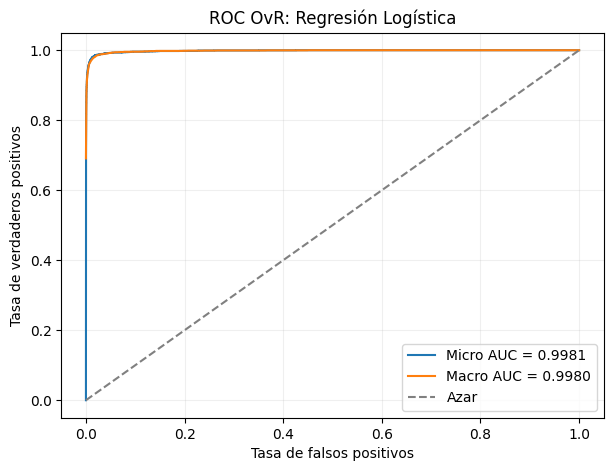

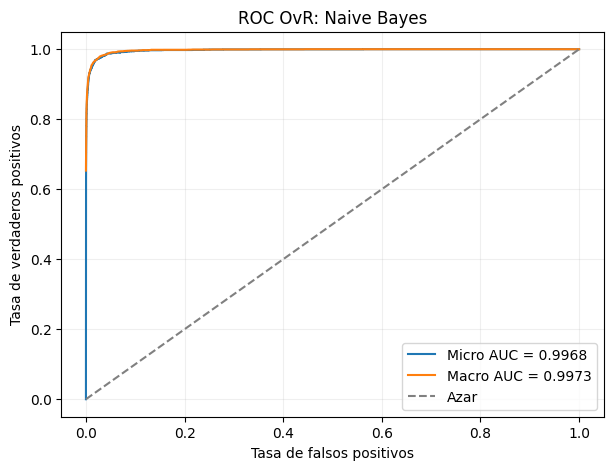

,modelo,auc_micro,auc_macro_ovr,auc_clases_promedio
0,Regresión Logística,0.998064,0.998050,0.998050
1,Naive Bayes,0.996836,0.997335,0.997335


In [2]:
def plot_roc(df, probs, labels, nombre):
    y=df['category'].astype(str).to_numpy()
    assert probs.shape==(len(y),len(labels))
    assert set(y).issubset(set(labels))
    binary=(y[:,None]==labels[None,:]).astype(int)
    assert np.all(binary.sum(axis=1)==1)
    fpr_micro,tpr_micro,_=roc_curve(binary.ravel(),probs.ravel())
    auc_micro=auc(fpr_micro,tpr_micro)
    grid=np.linspace(0,1,1001); tprs=[]; per_class=[]
    for i in range(len(labels)):
        fpr,tpr,_=roc_curve(binary[:,i],probs[:,i])
        tprs.append(np.interp(grid,fpr,tpr))
        per_class.append(auc(fpr,tpr))
    macro_curve=np.mean(tprs,axis=0)
    auc_macro=roc_auc_score(binary,probs,average='macro',multi_class='ovr')
    fig,ax=plt.subplots(figsize=(7,5))
    ax.plot(fpr_micro,tpr_micro,label=f'Micro AUC = {auc_micro:.4f}')
    ax.plot(grid,macro_curve,label=f'Macro AUC = {auc_macro:.4f}')
    ax.plot([0,1],[0,1],'--',color='gray',label='Azar')
    ax.set(xlabel='Tasa de falsos positivos',ylabel='Tasa de verdaderos positivos',title='ROC OvR: '+nombre)
    ax.legend();ax.grid(alpha=.2);plt.show()
    return {'modelo':nombre,'auc_micro':auc_micro,'auc_macro_ovr':auc_macro,'auc_clases_promedio':np.mean(per_class)}
roc_results=pd.DataFrame([plot_roc(log,P_L,labels_L,'Regresión Logística'),plot_roc(nb,P_N,labels_N,'Naive Bayes')])
display(roc_results)

**Interpretación de resultados ROC-AUC**
Los modelos evaluados presentan una elevada capacidad de discriminación entre las 77 intenciones bancarias. Regresión Logística alcanza un AUC macro de 0.9980, ligeramente superior al obtenido por Naive Bayes (0.9973).
Estos resultados, junto con las métricas de clasificación y validación cruzada, respaldan la selección de Regresión Logística como modelo principal. No obstante, su implementación operativa requiere considerar los errores de clasificación, los niveles de confianza y los mecanismos de revisión humana.


## 2. Simulación A/B retrospectiva (no desplegada)

Se realiza una simulación A/B retrospectiva utilizando las predicciones históricas de ambos modelos. Las observaciones se distribuyen aleatoriamente entre dos grupos: A (Naive Bayes) y B (Regresión Logística), con el propósito de comparar la proporción de clasificaciones correctas.
El análisis considera la diferencia de desempeño, un intervalo de confianza aproximado del 95% y una prueba estadística bilateral. Esta simulación constituye un ejercicio exploratorio y no representa un experimento implementado en producción, por lo que sus resultados no permiten establecer efectos causales sobre la experiencia de los clientes.


,grupo,n,aciertos,exactitud
0,A: Naive Bayes,1539,1303,0.846654
1,B: Regresión Logística,1540,1395,0.905844


Diferencia B-A: 0.0592; IC95% aproximado: [0.0360, 0.0824]; p bilateral: 6.127e-07


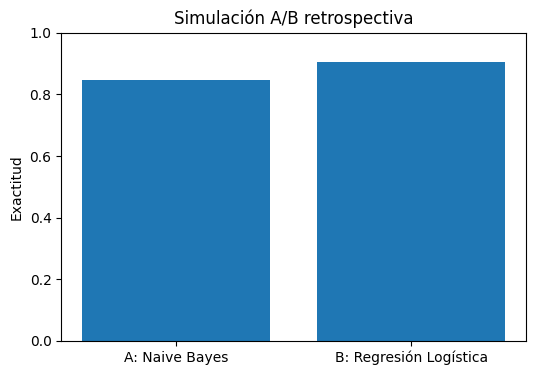

In [5]:
from scipy.stats import norm
rng=np.random.default_rng(2026)
assignment=rng.permutation(len(log))
A=assignment[:len(log)//2]; B=assignment[len(log)//2:]
accA=(nb.iloc[A]['prediccion'].astype(str).to_numpy()==nb.iloc[A]['category'].astype(str).to_numpy()).astype(int)
accB=(log.iloc[B]['prediccion'].astype(str).to_numpy()==log.iloc[B]['category'].astype(str).to_numpy()).astype(int)
pA,pB=accA.mean(),accB.mean(); diff=pB-pA
se=np.sqrt(pA*(1-pA)/len(A)+pB*(1-pB)/len(B))
ci=(diff-1.96*se,diff+1.96*se)
p_pool=(accA.sum()+accB.sum())/(len(A)+len(B))
se_null=np.sqrt(p_pool*(1-p_pool)*(1/len(A)+1/len(B)))
zstat=diff/se_null if se_null>0 else np.nan
pvalue=2*norm.sf(abs(zstat))
results=pd.DataFrame({'grupo':['A: Naive Bayes','B: Regresión Logística'],'n':[len(A),len(B)],'aciertos':[accA.sum(),accB.sum()],'exactitud':[pA,pB]})
display(results)
print(f'Diferencia B-A: {diff:.4f}; IC95% aproximado: [{ci[0]:.4f}, {ci[1]:.4f}]; p bilateral: {pvalue:.4g}')
fig,ax=plt.subplots(figsize=(6,4));ax.bar(results['grupo'],results['exactitud']);ax.set_ylim(0,1);ax.set_ylabel('Exactitud');ax.set_title('Simulación A/B retrospectiva');plt.show()

**Interpretación de resultados de la simulación A/B**
La simulación retrospectiva muestra un mejor desempeño de Regresión Logística, con una exactitud del 90.58%, frente al 84.67% de Naive Bayes. La diferencia de 5.92 puntos porcentuales es estadísticamente significativa (p < 0.001), con un intervalo de confianza aproximado del 95% entre 3.60 y 8.24 puntos porcentuales.
Estos resultados respaldan la selección de Regresión Logística como modelo principal para la clasificación de intenciones bancarias. Sin embargo, al tratarse de una simulación con datos históricos y grupos artificialmente divididos, no constituyen evidencia de su desempeño en producción. Se recomienda realizar posteriormente una prueba A/B controlada en un entorno operativo.

## 3. Interpretación y límites

•	Desempeño de los modelos: Ambos modelos presentan una elevada capacidad de discriminación entre las 77 intenciones bancarias. Regresión Logística obtiene mejores resultados y se posiciona como la alternativa más adecuada.

•	Interpretación de métricas: Un AUC elevado refleja una buena capacidad de discriminación, pero no garantiza la ausencia de errores de clasificación ni un desempeño equivalente en producción.

•	Limitaciones de la simulación A/B: El análisis utiliza datos históricos y grupos artificialmente divididos. Por tanto, sus resultados son exploratorios y no permiten establecer conclusiones causales sobre el impacto operativo.

•	Implicaciones para el negocio: Se recomienda una automatización gradual, con umbrales de confianza, revisión humana de casos inciertos y monitoreo de errores críticos.

•	Validación futura: Antes de implementar el modelo en producción, será necesario realizar una prueba A/B controlada que considere precisión, eficiencia operativa, experiencia del cliente y protección de datos personales.



**Conclusión:** Los resultados respaldan la selección de Regresión Logística como modelo principal, sujeto a validación operativa y mecanismos de supervisión que permitan una implementación confiable en el entorno bancario.
